# Problem 3.7

Consider the equation from Prob. 3.5 where we replace one of the coefficients with a parameter $a$ as follows:

$$r(u) = a u^3 - 6u^2 + 12u - 8 = 0.$$

a. Produce a plot similar to Fig. 3.12 by perturbing $a$ in the neighborhood of $a = 1.2$ using a solver convergence tolerance of $|r| \le 10^{-6}$.

b. *Exploration:* Try smaller tolerances and see how much you can decrease the numerical noise.

In [94]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [95]:
# implementation adapted from prob 3_5 with added factor a
a_default = 1.2 # global variable for the factor a

def residual(u, a=a_default):
    return a*u**3 - 6*u**2 + 12*u - 8

def derrivatie(u, a=a_default):
    return 3*a*u**2 - 12*u + 12

def solve_system(u0, max_iter=30, tol=1e-6, table=True):
    u = u0
    history = []                        # (iteration, u, residual)
    converged = False
    for i in range(max_iter):
        r = residual(u, a=a_default)
        history.append((i, u, r))       # update the history
        if abs(r) <= tol:               # converged when the residual is small
            converged = True            # stop iterating when r is below the tolerance
            break
        u = u - r / derrivatie(u, a=a_default)       # calculate u_k+1 for the next iteration

    if table:
        print(f"{'iter':>4} {'u':>14} {'r':>14}")
        for i_k, u_k, r_k in history:
            print(f"{i_k:4d} {u_k:14.8f} {r_k:14.8f}")
        print(f"{'converged' if converged else 'NOT converged'} after {i} iterations")
    return u, history

# quick test of the function
solve_system(2.0, table=True);

iter              u              r
   0     2.00000000     1.60000000
   1     1.33333333     0.17777778
   2     1.25925926    -0.00707209
   3     1.26198188    -0.00001085
   4     1.26198607    -0.00000000
converged after 4 iterations


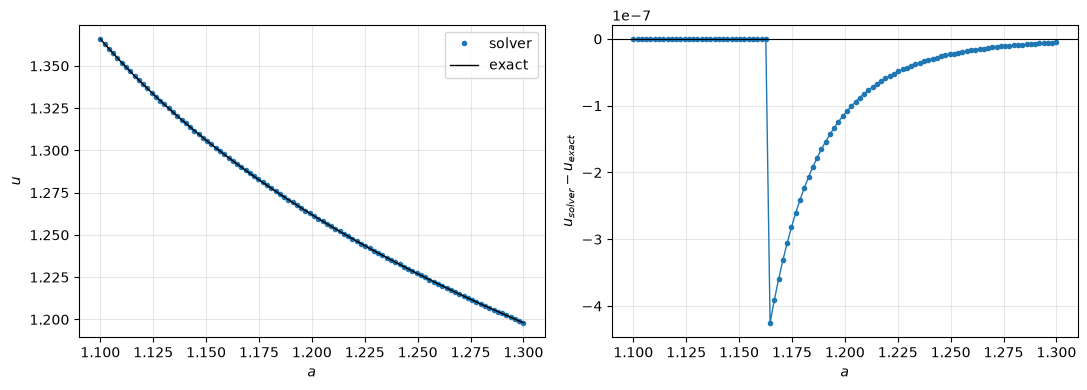

In [96]:
# a) perturbation of a around 1.2 and see how the solution changes
a_values = 1.2 + np.linspace(-0.1, 0.1, 100)
results = [] # a and corresponding u values
for a in a_values:
    a_default = a
    u, _ = solve_system(3.0, table=False)
    results.append((a, u))
a_arr, u_arr = np.array(results).T

u_smooth = 2 / (1 - np.cbrt(1 - a_arr))     # exact real root, np.cbrt handles negative arguments
noise = u_arr - u_smooth

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(a_arr, u_arr, "o", ms=3, label="solver")
axes[0].plot(a_arr, u_smooth, "k-", lw=1, label="exact")
axes[0].set_ylabel("$u$")
axes[0].legend()

axes[1].plot(a_arr, noise, "o-", ms=3, lw=1)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_ylabel("$u_{solver} - u_{exact}$")

for ax in axes:
    ax.set_xlabel("$a$")
    ax.grid(alpha=0.3)
    ax.ticklabel_format(axis="x", useOffset=False, style="plain")
plt.tight_layout()
plt.show()

a) interpretation  
the noise is on the order of 1e-7. there is a big spike around a = 1.16 which comes from numerical noise from the roundoff

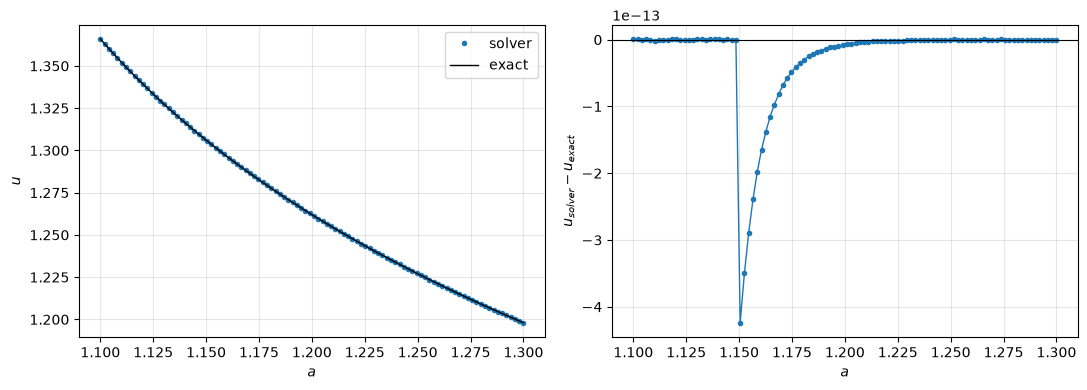

In [97]:
# b) smaller tolerance and see how the solution changes

a_values = 1.2 + np.linspace(-0.1, 0.1, 100)
results = [] # a and corresponding u values
for a in a_values:
    a_default = a
    u, _ = solve_system(3.0, tol=1e-12, table=False)
    results.append((a, u))
a_arr, u_arr = np.array(results).T

u_smooth = 2 / (1 - np.cbrt(1 - a_arr))     # exact real root, np.cbrt handles negative arguments
noise = u_arr - u_smooth

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(a_arr, u_arr, "o", ms=3, label="solver")
axes[0].plot(a_arr, u_smooth, "k-", lw=1, label="exact")
axes[0].set_ylabel("$u$")
axes[0].legend()

axes[1].plot(a_arr, noise, "o-", ms=3, lw=1)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_ylabel("$u_{solver} - u_{exact}$")

for ax in axes:
    ax.set_xlabel("$a$")
    ax.grid(alpha=0.3)
    ax.ticklabel_format(axis="x", useOffset=False, style="plain")
plt.tight_layout()
plt.show()

b) interpretation
when we apply a tolerance of 1e-12 we get a much smaller noise function. this time we are on the oder of 1e-13 off instead of 1e-7. a significant improvement. at a = 1.15 there is a massive step in the error. this numerical noise from the roundoff

## Results

see above

## Interpretation

knowing the error level of the model is crucial. it limits how well we can optimize.